# Closure test of the point-source folding with background

In an unbinned fit with a dominant background, any mismatch between the integral of the
source density over the selected data space and the expected counts `S`,
`c = (int s dx) / S`, biases the flux by `dK/K ~ (c - 1) B_eff / S`, about 10 times `c - 1`
for the Crab in 3 h. Signal-only fits are immune (`K = N / S`).

This notebook generates Crab events from the IRF itself (`simulate_point_source_events`,
real `hist_simple` response and attitude, 3 h) plus an ideal background with a known density
(`IsotropicPowerLawBackground`), and fits them with the broadened Trapz folding and that
background model. Since the events come from the same IRF, any bias comes from the folding.

- `c` is measured with the background events as importance samples: their density is known
  exactly, so `c = mean(s / b_norm) / S` over them, with `b_norm` the normalized background
  density.
- The fits of 80 realizations, with and without the background, give the bias of the flux and
  index.

In [1]:
import gc
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.time import Time
from astromodels import Powerlaw, PointSource
from scipy.optimize import minimize

from cosipy.background_estimation.analytic_background import IsotropicPowerLawBackground
from cosipy.data_io.EmCDSUnbinnedData import TimeTagEmCDSEventDataInSCFrameFromArrays
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.response.broadened_irf_cache import BroadenedIRFCache
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized
from cosipy.source_injector.point_source_events import simulate_point_source_events
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml.psr_fixed_ei import UnbinnedThreeMLPointSourceResponseTrapz

# divide-by-zero warnings of the empty phase-space bins, once per evaluation
warnings.filterwarnings('ignore', category=RuntimeWarning)

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
data_path = Path('/home/user/dc4data')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'

erange = (200., 5000.)
selection = EnergySelector(erange * u.keV)
tstart, tstop = Time('2028-03-23 10:36:00'), Time('2028-03-23 13:36:00')
sc = SpacecraftHistory.open(data_path / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits')
sc = sc.select_interval(tstart, tstop)

K_true, index_true, piv = 2.5e-6, -2.2, 1000.
spectrum = Powerlaw(index=index_true, K=K_true, piv=piv)
spectrum.K.unit = 1 / u.cm ** 2 / u.s / u.keV
spectrum.piv.unit = u.keV
source = PointSource('Crab', l=184.56, b=-5.78, spectral_shape=spectrum)

bkg_rate, bkg_index = 12.29 * u.Hz, -2.  # about the DC4 rate in this window, after the cut
nreal = 80

irf = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection)

## Realizations

Crab photons over 100 keV - 10 MeV, events from the IRF (conditional on the cut), plus the
background events.

In [3]:
t0 = time.time()
realizations = []
for r in range(nreal):
    rng = np.random.default_rng(r)
    crab, _ = simulate_point_source_events(irf, sc, source, energy_range_keV=(100., 10_000.), rng=rng)
    bkg = IsotropicPowerLawBackground.random_events(sc, bkg_rate, bkg_index, erange, rng)
    realizations.append((crab, bkg))
print(f'{time.time() - t0:.0f} s; per realization: {np.mean([c.nevents for c, _ in realizations]):.0f} Crab, '
      f'{np.mean([b.nevents for _, b in realizations]):.0f} background events')

3254 s; per realization: 1603 Crab, 119225 background events


The events of `chunk` realizations go in one data set, so the folding (the expensive part)
is computed once per chunk; each realization is fitted with its own events. Chunks keep the
memory in bounds.

`c` uses `int s dx = E_b[s / b_norm]` over the background events, for the true spectrum.
The fits maximize the unbinned likelihood `sum log(s_i + b_i) - S - B` over the events of
each realization, with free `K`, index and background rate (and `K`, index alone for the
signal-only fits of the Crab events).

In [4]:
def concatenate(datasets):
    arrays = [np.concatenate([np.asarray(getattr(d, name), dtype=float) for d in datasets])
              for name in ('energy_keV', 'scattered_lon_rad_sc', 'scattered_lat_rad_sc', 'scattering_angle_rad')]
    t = Time(np.concatenate([d.time.utc.unix for d in datasets]), format='unix', scale='utc')
    return TimeTagEmCDSEventDataInSCFrameFromArrays(t.jd1, t.jd2, *arrays)


def set_spectrum(log_k, index):
    spectrum.K.value = np.exp(log_k)
    spectrum.index.value = index


def fit(psr, bkg_model, livetime, idx, with_background):
    def negloglike(x):
        set_spectrum(x[0], x[1])
        s = np.asarray(psr.expectation_density())[idx]
        S = psr.expected_counts()
        if with_background:
            rate = np.exp(x[2])
            return -(np.sum(np.log(s + rate * bkg_model._density_per_rate[idx])) - S - rate * livetime)
        return -(np.sum(np.log(s)) - S)

    x0 = [np.log(K_true), index_true] + ([np.log(bkg_rate.to_value(u.Hz))] if with_background else [])
    result = minimize(negloglike, x0, method='Nelder-Mead', options=dict(xatol=1e-5, fatol=1e-4, maxiter=4000))
    set_spectrum(np.log(K_true), index_true)
    return result.x


cache = BroadenedIRFCache(IRFRelativeHistUnpolarized.from_h5(irf_file), energy_range_keV=(100., 10_000.))
cells = UnbinnedThreeMLPointSourceResponseTrapz.cells_for(source, cache, accuracy=1e-3)
livetime = sc.cumulative_livetime().to_value(u.s)

chunk = 20
weights, with_bkg, signal_only = [], [], []
t0 = time.time()
for first in range(0, nreal, chunk):
    pairs = realizations[first:first + chunk]
    datasets = [d for pair in pairs for d in pair]
    data = concatenate(datasets)
    offsets = np.concatenate([[0], np.cumsum([d.nevents for d in datasets])])
    crab_idx = [np.arange(offsets[2 * r], offsets[2 * r + 1]) for r in range(len(pairs))]
    bkg_idx = [np.arange(offsets[2 * r + 1], offsets[2 * r + 2]) for r in range(len(pairs))]

    psr = UnbinnedThreeMLPointSourceResponseTrapz(data, irf, sc, cache, cells, offset=None)
    psr.set_source(source)
    psr.init_cache()

    bkg_model = IsotropicPowerLawBackground(data, sc, bkg_rate, bkg_index, erange)
    b_norm = np.asarray(bkg_model.expectation_density()) / bkg_model.expected_counts()  # integrates to 1
    s = np.asarray(psr.expectation_density())
    S = psr.expected_counts()
    weights += [s[i] / b_norm[i] / S for i in bkg_idx]

    with_bkg += [fit(psr, bkg_model, livetime, np.concatenate([c, b]), True) for c, b in zip(crab_idx, bkg_idx)]
    signal_only += [fit(psr, bkg_model, livetime, c, False) for c in crab_idx]

    del psr, bkg_model, data, datasets, s, b_norm
    gc.collect()
    print(f'realizations {first}-{first + len(pairs) - 1}: {time.time() - t0:.0f} s')

with_bkg, signal_only = np.array(with_bkg), np.array(signal_only)
w = np.concatenate(weights)
c, c_err = w.mean(), w.std() / np.sqrt(w.size)
print(f'{len(cells)} cells; S = {S:.1f}, c = {c:.4f} +- {c_err:.4f}')

realizations 0-19: 3401 s


realizations 20-39: 5957 s


realizations 40-59: 9007 s


realizations 60-79: 12401 s
16 cells; S = 1605.5, c = 1.0000 +- 0.0011


In [5]:
for name, x in (('with background', with_bkg), ('signal only', signal_only)):
    k = np.exp(x[:, 0]) / K_true - 1
    idx = x[:, 1] - index_true
    print(f'{name:16s}  K/K_true - 1 = {k.mean():+.3f} +- {k.std(ddof=1) / np.sqrt(nreal):.3f}   '
          f'index - true = {idx.mean():+.3f} +- {idx.std(ddof=1) / np.sqrt(nreal):.3f}')
print(f'background rate / true - 1 = {(np.exp(with_bkg[:, 2]) / bkg_rate.to_value(u.Hz) - 1).mean():+.4f}')

with background   K/K_true - 1 = -0.010 +- 0.017   index - true = -0.013 +- 0.018
signal only       K/K_true - 1 = +0.003 +- 0.003   index - true = +0.004 +- 0.003
background rate / true - 1 = -0.0004


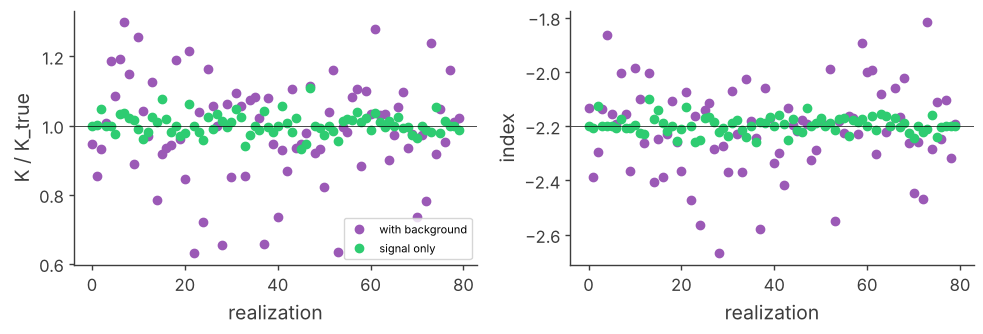

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, label, true in ((axs[0], 0, 'K / K_true', None), (axs[1], 1, 'index', index_true)):
    for x, name in ((with_bkg, 'with background'), (signal_only, 'signal only')):
        v = np.exp(x[:, 0]) / K_true if col == 0 else x[:, 1]
        ax.plot(np.arange(nreal), v, 'o', label=name)
    ax.axhline(1 if col == 0 else true, color='k', lw=0.5)
    ax.set_xlabel('realization')
    ax.set_ylabel(label)
axs[0].legend()
fig.tight_layout()

`c` is consistent with 1, and the fitted flux and index with background agree with the
injected ones within the scatter of the realizations, like the signal-only fits. Before the
cleanup, the per-event Trapz nodes of #15 gave `c = 1.008` and `K` +12% in the same test.

The attitude is sampled every second (`attitude_step`, default 1 s) for the density of each
event and for `S`: the source moves up to ~1 deg per 15 s interval of the history (several
deg during slews). With 40 realizations, the first half of these (seeds 0-39) gave -5% +- 2%
in `K` and -0.06 +- 0.02 in the index with background, with either the 15 s midpoints or 1 s
samples, while another independent set (seeds 1000-1039) gave +2% +- 2.5% and +0.02 +- 0.02:
a fluctuation of one set of realizations, which is why there are 80 here.